# Stage 1, HW 4 — H2a: which Ring traps do human groups use?
A **trap** is a sign pattern with no zeros, both signs present, and no node that wants to switch (c · (c @ A) ≥ 0). On the Ring a trap is either a 5-2 split or a 4-3 split. Fraught rows are trap rows; we compare how often each kind is visited and how often it is fraught.

In [1]:
# Stage 1, HW 4
import numpy as np
import pandas as pd
from slider import config
from slider import slider_logs as sl
from slider.fraught import trap_sums, sums_hold, sums_interp, trap_mask
from slider.stats import trap_table, ratios

table = pd.read_csv(config.RUNS_TABLE)
runs = sl.parse_all()   # same order as the rows of runs_table.csv
assert all(run["file"] == f and run["wave"] == w for run, f, w in zip(runs, table["file"], table["wave"]))

# Ring runs in CL and EL, with an end marker, and not the 1-row aborted rounds
keep = (table["topology"] == "Ring") & table["dataset"].isin(["CL", "EL"]) & (table["end"] != "incomplete") & (table["T"] > 1)
print(keep.sum(), "runs")

109 runs


`fraught_mask` and `trap_sums` are in `src/slider/fraught.py`. `trap_sums` adds up the time spent in each kind of trap and of fraught state.

Two ways to weight the rows, as in HW 3: forward hold (each row lasts until the next) and interpolation (1001 evenly spaced times, equal weights).

In [2]:
# per-run sums for both methods, saved to ring_traps.csv
rows = []
for i in table.index[keep]:
    hold, interp = sums_hold(i, runs, table), sums_interp(i, runs)
    rows.append({"file": table["file"][i], "dataset": table["dataset"][i], "wave": table["wave"][i],
                 **hold, **{k + " interp": v for k, v in interp.items()}})
per_run = pd.DataFrame(rows)
per_run.to_csv(config.RING_TRAPS, index=False)
per_run.round(2)

,file,dataset,wave,T52,T43,F52,F43,T52 interp,T43 interp,F52 interp,F43 interp
0,log_Fri Sep 16 161000 EDT 2016.txt,CL,1,42.00,66.0,7.00,28.00,43.05,69.47,6.83,29.61
1,log_Fri Sep 16 161000 EDT 2016.txt,CL,6,16.00,7.0,1.00,2.00,16.10,6.94,1.05,1.05
2,log_Fri Sep 16 161000 EDT 2016.txt,CL,8,40.00,14.0,13.00,2.00,39.94,14.10,10.87,1.91
3,log_Fri Sep 16 165753 EDT 2016.txt,CL,1,48.60,92.2,14.50,57.90,49.64,94.15,14.12,58.42
4,log_Fri Sep 16 165753 EDT 2016.txt,CL,6,86.41,82.0,35.09,59.69,88.10,83.65,31.74,60.21
...,...,...,...,...,...,...,...,...,...,...,...
104,log_v09_Wed Sep 28 163724 EDT 2016.txt,CL,6,36.50,67.0,17.80,48.60,38.45,73.46,15.50,52.99
105,log_v09_Wed Sep 28 163724 EDT 2016.txt,CL,8,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00
106,log_v09_Wed Sep 28 173239 EDT 2016.txt,CL,5,41.50,61.7,28.40,44.00,44.07,65.17,28.97,45.73
107,log_v09_Wed Sep 28 173239 EDT 2016.txt,CL,7,5.40,1.7,0.00,0.00,5.59,1.81,0.00,0.00


Pooled time in each kind, then the three ratios. Baselines: P(4-3|F) is 50% if the fraught 4-3 and 5-2 states were equally likely, 75% if in proportion to their volume; occupancy 50%; P(F|4-3) = 1/12 and P(F|5-2) = 1/36.

In [3]:
print("forward hold (seconds)")
trap_table(per_run).round(2)

forward hold (seconds)


,runs,T52,T43,F52,F43,"P(4-3|F) % [50 unif, 75 vol]",occupancy 4-3 % [50],P(F|4-3) % [8.33],P(F|5-2) % [2.78]
pooled,109,2203.24,2581.29,1000.26,1912.96,65.66,53.95,74.11,45.40
CL,58,1236.56,1211.73,469.03,802.98,63.13,49.49,66.27,37.93
EL,51,966.68,1369.56,531.23,1109.98,67.63,58.62,81.05,54.95


In [4]:
# same table with the interpolation method (check)
print("interpolation (seconds)")
trap_table(per_run, " interp").round(2)

interpolation (seconds)


,runs,T52,T43,F52,F43,"P(4-3|F) % [50 unif, 75 vol]",occupancy 4-3 % [50],P(F|4-3) % [8.33],P(F|5-2) % [2.78]
pooled,109,2302.32,2720.11,905.68,1970.01,68.51,54.16,72.42,39.34
CL,58,1285.43,1269.15,429.75,820.82,65.64,49.68,64.67,33.43
EL,51,1016.90,1450.97,475.93,1149.19,70.71,58.79,79.20,46.80


## 4.3 How sure are we, and where do players sit in a trap?
**Part A.** Bootstrap over groups (a group = one log file): resample the groups with replacement 10,000 times, add up F52, F43, T52, T43 over all their Ring runs, and recompute the ratios. thick/thin = P(F|4-3) / P(F|5-2), baseline (1/12) / (1/36) = 3.0.

In [5]:
# 4.3 A: bootstrap over groups (group = one log file), 10,000 resamples, fixed seed
per_run = pd.read_csv(config.RING_TRAPS)

rows = []
for label, datasets in [("pooled", ["CL", "EL"]), ("CL", ["CL"]), ("EL", ["EL"])]:
    d = per_run[per_run["dataset"].isin(datasets)]
    for method, suffix in [("hold", ""), ("interp", " interp")]:
        g = d.groupby("file")[[k + suffix for k in ["F52", "F43", "T52", "T43"]]].sum().values   # one row per group
        rng = np.random.default_rng(0)
        idx = rng.integers(0, len(g), size=(10000, len(g)))      # draw groups with replacement
        boot = np.array(ratios(*g[idx].sum(axis=1).T))            # 3 x 10000 ratios
        low, high = np.percentile(boot, [2.5, 97.5], axis=1)      # 95% CI
        est = ratios(*g.sum(axis=0))                              # point estimate from all groups
        rows.append([label, method, len(g), (g[:, 0] + g[:, 1] > 0).sum(),
                     est[0], low[0], high[0], not low[0] <= 50 <= high[0], not low[0] <= 75 <= high[0],
                     est[1], low[1], high[1],
                     est[2], low[2], high[2], not low[2] <= 3 <= high[2]])

boot_table = pd.DataFrame(rows, columns=["dataset", "method", "groups", "groups with fraught",
    "P(4-3|F) %", "P low", "P high", "P excl 50", "P excl 75",
    "occupancy %", "occ low", "occ high",
    "thick/thin", "tt low", "tt high", "tt excl 3.0"])
boot_table.round(2)

,dataset,method,groups,groups with fraught,P(4-3|F) %,P low,P high,P excl 50,P excl 75,occupancy %,occ low,occ high,thick/thin,tt low,tt high,tt excl 3.0
0,pooled,hold,37,36,65.66,61.71,69.41,True,True,53.95,49.20,58.62,1.63,1.49,1.80,True
1,pooled,interp,37,36,68.51,64.94,71.76,True,True,54.16,49.43,58.80,1.84,1.65,2.04,True
2,CL,hold,20,19,63.13,58.92,66.80,True,True,49.49,44.38,54.20,1.75,1.52,2.00,True
3,CL,interp,20,19,65.64,61.74,69.37,True,True,49.68,44.71,54.15,1.93,1.65,2.26,True
4,EL,hold,17,17,67.63,61.29,73.18,True,True,58.62,51.04,65.59,1.47,1.34,1.66,True
5,EL,interp,17,17,70.71,65.22,75.13,True,False,58.79,51.14,65.72,1.69,1.47,1.95,True


**Part B.** Do players sit near the slider ends while in a trap? Forward-hold weights, every player counts. If |s_i| were uniform on [0, 1], 10% of player-time would be at |s_i| ≥ 0.9 and the mean would be 0.5.

In [6]:
# 4.3 B: |s_i| on trap rows and on all rows, forward-hold weights
a, w, trap, ds = [], [], [], []
for i in table.index[keep]:
    run = runs[i]
    t = run["t"]
    T_end = t[-1] if table["success"][i] else max(300, t[-1])
    dt = np.diff(np.append(t, T_end))                    # forward hold
    a.append(np.abs(sl.sign_correct(run)).ravel())      # |s_i|, row by row (7 values per row)
    w.append(np.repeat(dt, 7))                          # each player gets the row's duration
    trap.append(np.repeat(trap_mask(run), 7))
    ds.append(np.repeat(table["dataset"][i], 7 * len(t)))
a, w, trap, ds = map(np.concatenate, [a, w, trap, ds])

out = {}
for label, datasets in [("pooled", ["CL", "EL"]), ("CL", ["CL"]), ("EL", ["EL"])]:
    m = np.isin(ds, datasets)
    out[label] = {}
    for rows_name, r in [("trap", m & trap), ("all", m)]:
        out[label][rows_name + ": % |s| >= 0.9  [10]"] = 100 * np.sum(w[r] * (a[r] >= 0.9)) / np.sum(w[r])
        out[label][rows_name + ": mean |s|  [0.5]"] = np.sum(w[r] * a[r]) / np.sum(w[r])
pd.DataFrame(out).T.round(3)

,trap: % |s| >= 0.9 [10],trap: mean |s| [0.5],all: % |s| >= 0.9 [10],all: mean |s| [0.5]
pooled,77.777,0.876,69.583,0.796
CL,73.277,0.852,66.480,0.776
EL,82.493,0.902,73.310,0.821


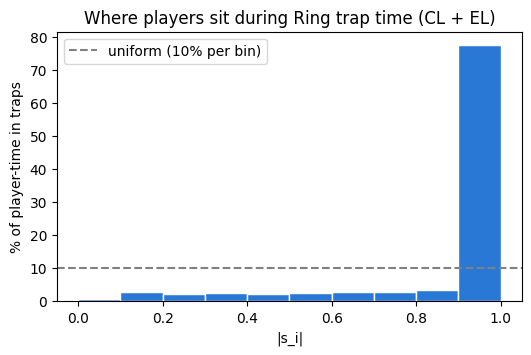

last bin = 77.8 %


In [7]:
# figure: time-weighted histogram of |s_i| during trap time (pooled), bins of 0.1
import matplotlib.pyplot as plt

bins = np.round(np.linspace(0, 1, 11), 10)   # rounded so values like 0.3 fall in [0.3, 0.4), not [0.2, 0.3)
h, _ = np.histogram(a[trap], bins=bins, weights=w[trap])
plt.figure(figsize=(6, 3.5))
plt.bar(bins[:-1], 100 * h / h.sum(), width=0.1, align="edge", color="#2a78d6", edgecolor="white")
plt.axhline(10, color="gray", linestyle="--", label="uniform (10% per bin)")
plt.xlabel("|s_i|")
plt.ylabel("% of player-time in traps")
plt.title("Where players sit during Ring trap time (CL + EL)")
plt.legend()
plt.show()
print("last bin = %.1f %%" % (100 * h[-1] / h.sum()))   # same as the trap share with |s| >= 0.9